In [1]:
import os
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter
from pathlib import Path
from copy import deepcopy
import itertools

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import MobileNet_V2_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Grad-CAM specific libraries
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Select Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

Using compute device: cpu


In [2]:
# Update this path to your actual dataset location
DATASET_DIR = Path("/home/gabor-levai/Downloads/AI_VIS/archive (3)")
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
records = []

if not DATASET_DIR.exists():
    print("Warning: Directory not found. Please update DATASET_DIR.")

for filepath in DATASET_DIR.rglob("*"):
    if filepath.is_file() and filepath.suffix.lower() in valid_extensions:
        parts_lower = [p.lower() for p in filepath.parts]
        
        if any("real" in p for p in parts_lower):
            label = "Real"
        elif any("fake" in p for p in parts_lower):
            label = "Fake"
        else:
            label = "Unknown"
            
        records.append({"filepath": str(filepath), "label": label})

df = pd.DataFrame(records)
df_filtered = df[df["label"].isin(["Real", "Fake"])].copy()

# Split into Training (80%) and Testing/Validation (20%)
if len(df_filtered) > 0:
    train_df, test_df = train_test_split(df_filtered, test_size=0.2, random_state=42, stratify=df_filtered["label"])
else:
    print("No valid images found. Creating empty dataframes for demonstration.")
    train_df, test_df = pd.DataFrame(), pd.DataFrame()

In [3]:
class DeepfakeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label_map = {"Real": 1, "Fake": 0}
        
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        img_path = self.dataframe.loc[idx, "filepath"]
        label_str = self.dataframe.loc[idx, "label"]
        image = Image.open(img_path).convert('RGB')
        label = self.label_map[label_str]
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32), img_path

# Base Transforms
base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

if len(train_df) > 0:
    train_dataset = DeepfakeDataset(train_df, transform=train_transform)
    test_dataset = DeepfakeDataset(test_df, transform=base_transform)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    print(f"DataLoaders ready: {len(train_dataset)} train samples, {len(test_dataset)} test samples.")

DataLoaders ready: 1632 train samples, 409 test samples.


In [4]:
learning_rates = [1e-4, 5e-5]
weight_decays = [0.0, 1e-4]
num_epochs = 5

best_val_loss = float('inf')
best_model_state = None
best_params = {}
history = {}

print("Starting Hyperparameter Tuning on MobileNetV2...")

for lr, wd in itertools.product(learning_rates, weight_decays):
    print(f"\nTraining with LR: {lr}, Weight Decay: {wd}")
    model = models.mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
    # MobileNetV2 uses a classifier sequence; index 1 is the linear layer
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)
    model = model.to(device)
    
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    
    train_losses = []
    val_losses = []
    
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        
        if len(train_df) == 0: 
            print("Dataset empty. Skipping training.")
            break 
            
        for images, labels, _ in train_loader:
            images, labels = images.to(device), labels.to(device).unsqueeze(1)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            
        epoch_train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)
        
        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, labels, _ in test_loader:
                images, labels = images.to(device), labels.to(device).unsqueeze(1)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
        epoch_val_loss = val_loss / len(test_loader.dataset)
        val_losses.append(epoch_val_loss)
        
        print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}")
        
    history[(lr, wd)] = {'train': train_losses, 'val': val_losses}
    
    if len(train_df) > 0 and val_losses[-1] < best_val_loss:
        best_val_loss = val_losses[-1]
        best_model_state = deepcopy(model.state_dict())
        best_params = {'lr': lr, 'wd': wd}

if best_model_state:
    torch.save(best_model_state, 'best_mobilenetv2.pth')
    print(f"\nBest Model Saved with Params: {best_params}, Val Loss: {best_val_loss:.4f}")

Starting Hyperparameter Tuning on MobileNetV2...

Training with LR: 0.0001, Weight Decay: 0.0
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /home/gabor-levai/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 27.8MB/s]


Epoch 1/5 - Train Loss: 0.6813, Val Loss: 0.6501
Epoch 2/5 - Train Loss: 0.5927, Val Loss: 0.6049
Epoch 3/5 - Train Loss: 0.4864, Val Loss: 0.5855
Epoch 4/5 - Train Loss: 0.3537, Val Loss: 0.5652
Epoch 5/5 - Train Loss: 0.2264, Val Loss: 0.6154

Training with LR: 0.0001, Weight Decay: 0.0001
Epoch 1/5 - Train Loss: 0.6812, Val Loss: 0.6496
Epoch 2/5 - Train Loss: 0.5894, Val Loss: 0.6009
Epoch 3/5 - Train Loss: 0.4779, Val Loss: 0.5665
Epoch 4/5 - Train Loss: 0.3465, Val Loss: 0.5306
Epoch 5/5 - Train Loss: 0.2093, Val Loss: 0.5916

Training with LR: 5e-05, Weight Decay: 0.0
Epoch 1/5 - Train Loss: 0.6879, Val Loss: 0.6742
Epoch 2/5 - Train Loss: 0.6507, Val Loss: 0.6492
Epoch 3/5 - Train Loss: 0.6016, Val Loss: 0.6161
Epoch 4/5 - Train Loss: 0.5419, Val Loss: 0.5959
Epoch 5/5 - Train Loss: 0.4705, Val Loss: 0.5792

Training with LR: 5e-05, Weight Decay: 0.0001
Epoch 1/5 - Train Loss: 0.6873, Val Loss: 0.6708
Epoch 2/5 - Train Loss: 0.6420, Val Loss: 0.6427
Epoch 3/5 - Train Loss: 0.59

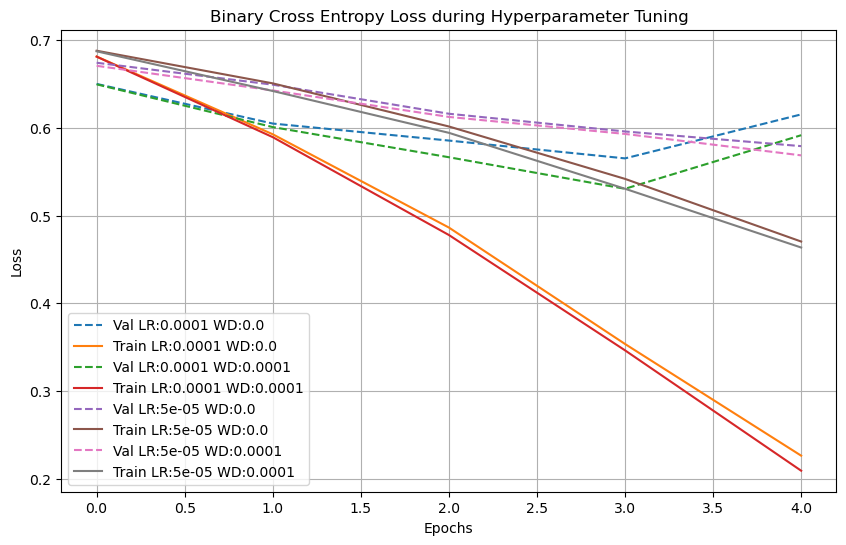

In [5]:
plt.figure(figsize=(10, 6))
if history:
    for (lr, wd), losses in history.items():
        if losses['val'] and losses['train']:
            plt.plot(losses['val'], label=f'Val LR:{lr} WD:{wd}', linestyle='--')
            plt.plot(losses['train'], label=f'Train LR:{lr} WD:{wd}')
        
    plt.title('Binary Cross Entropy Loss during Hyperparameter Tuning')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No history to plot.")

In [6]:
def apply_corruption(image_path, corruption_type, strength):
    img = Image.open(image_path).convert('RGB')
    if corruption_type == 'jpeg':
        quality = 100 - (strength * 20)
        img.save("temp.jpg", "JPEG", quality=quality)
        img = Image.open("temp.jpg")
    elif corruption_type == 'blur':
        img = img.filter(ImageFilter.GaussianBlur(radius=strength))
    elif corruption_type == 'noise':
        img_arr = np.array(img)
        noise = np.random.normal(0, strength * 10, img_arr.shape)
        img_arr = np.clip(img_arr + noise, 0, 255).astype(np.uint8)
        img = Image.fromarray(img_arr)
    elif corruption_type == 'resize':
        orig_size = img.size
        scale = 1.0 - (strength * 0.15)
        small_img = img.resize((int(orig_size[0]*scale), int(orig_size[1]*scale)), Image.BILINEAR)
        img = small_img.resize(orig_size, Image.BILINEAR)
    return base_transform(img)

corruptions = ['jpeg', 'blur', 'noise', 'resize']
strengths = [1, 2, 3, 4]

print("Robustness pipeline constructed for: JPEG Compression, Gaussian Blur, Downsize-and-Resize, Gaussian Noise.")

Robustness pipeline constructed for: JPEG Compression, Gaussian Blur, Downsize-and-Resize, Gaussian Noise.


Running inference on the test dataset...

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Fake (0)       0.73      0.58      0.65       192
    Real (1)       0.69      0.81      0.74       217

    accuracy                           0.70       409
   macro avg       0.71      0.69      0.69       409
weighted avg       0.71      0.70      0.70       409



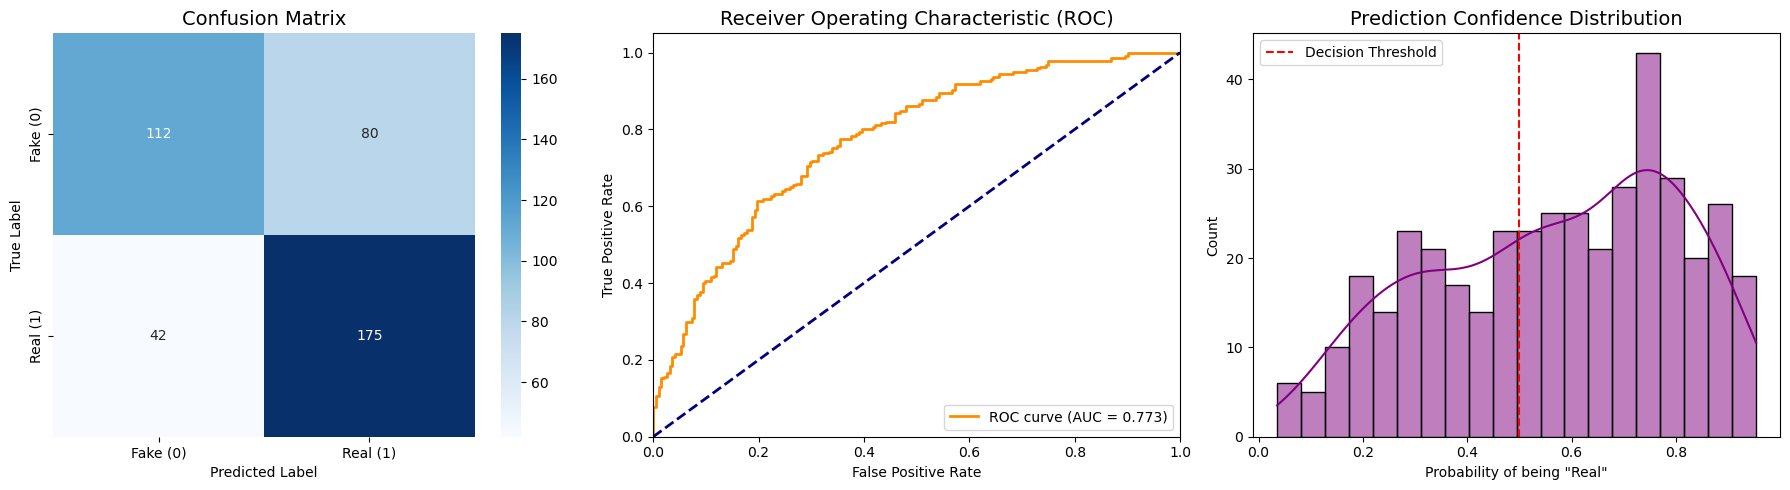


SAMPLE PREDICTIONS (GREEN = Correct, RED = Incorrect)


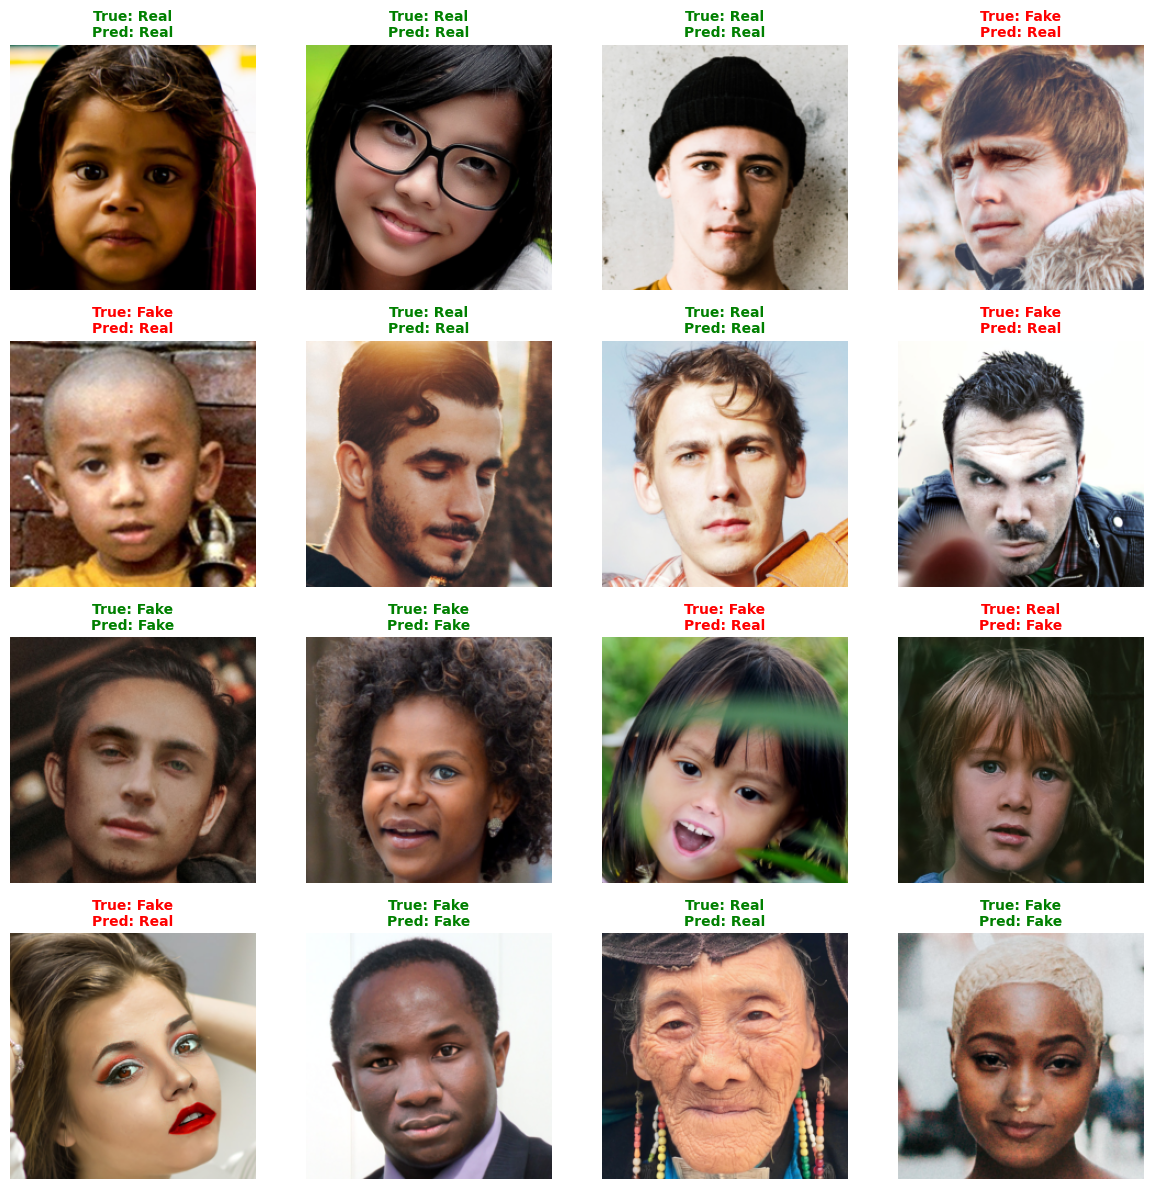

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch

# 1. Load the Best Model
if 'best_model_state' in locals() and best_model_state:
    model = models.mobilenet_v2(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)
    model.load_state_dict(torch.load('best_mobilenetv2.pth'))
else:
    print("Loading model from disk...")
    model = models.mobilenet_v2(weights=None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)
    # Ensure the path matches where you saved it
    model.load_state_dict(torch.load('best_mobilenetv2.pth', map_location=device))

model = model.to(device)
model.eval()

# 2. Perform Inference on the Test Set
all_labels = []
all_preds = []
all_probs = []
vis_images = []
vis_labels = []
vis_preds = []

print("Running inference on the test dataset...")
with torch.no_grad():
    for images, labels, _ in test_loader:
        images, labels = images.to(device), labels.to(device).unsqueeze(1)
        outputs = model(images)
        
        # Apply sigmoid to get probabilities between 0 and 1
        probs = torch.sigmoid(outputs)
        # Convert probabilities to binary predictions (Threshold = 0.5)
        preds = (probs >= 0.5).float()
        
        all_probs.extend(probs.cpu().numpy().flatten())
        all_preds.extend(preds.cpu().numpy().flatten())
        all_labels.extend(labels.cpu().numpy().flatten())
        
        # Save the first batch for visual plotting
        if len(vis_images) < 16: 
            vis_images.extend(images.cpu())
            vis_labels.extend(labels.cpu().numpy().flatten())
            vis_preds.extend(preds.cpu().numpy().flatten())

# 3. Print Statistical Report
print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
# 1 = Real, 0 = Fake (based on the mapping in your dataset class)
target_names = ['Fake (0)', 'Real (1)']
print(classification_report(all_labels, all_preds, target_names=target_names))

# 4. Generate Useful Graphs
fig = plt.figure(figsize=(18, 5))

# Graph A: Confusion Matrix
ax1 = plt.subplot(1, 3, 1)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=ax1)
ax1.set_title('Confusion Matrix', fontsize=14)
ax1.set_xlabel('Predicted Label')
ax1.set_ylabel('True Label')

# Graph B: ROC Curve
ax2 = plt.subplot(1, 3, 2)
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = auc(fpr, tpr)
ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Receiver Operating Characteristic (ROC)', fontsize=14)
ax2.legend(loc="lower right")

# Graph C: Prediction Confidence Distribution
ax3 = plt.subplot(1, 3, 3)
sns.histplot(all_probs, bins=20, kde=True, color='purple', ax=ax3)
ax3.axvline(0.5, color='red', linestyle='--', label='Decision Threshold')
ax3.set_title('Prediction Confidence Distribution', fontsize=14)
ax3.set_xlabel('Probability of being "Real"')
ax3.set_ylabel('Count')
ax3.legend()

plt.tight_layout()
plt.show()

# 5. Visualizing Specific Photo Predictions
print("\n" + "="*50)
print("SAMPLE PREDICTIONS (GREEN = Correct, RED = Incorrect)")
print("="*50)

# Helper function to un-normalize images for viewing
def imshow_unnormalized(img):
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# Plot a 4x4 grid of the first 16 images
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
label_map_rev = {1.0: "Real", 0.0: "Fake"}

for i, ax in enumerate(axes.flat):
    if i < len(vis_images):
        img_display = imshow_unnormalized(vis_images[i])
        ax.imshow(img_display)
        
        true_lbl = label_map_rev[vis_labels[i]]
        pred_lbl = label_map_rev[vis_preds[i]]
        
        # Color the title green if correct, red if wrong
        color = "green" if true_lbl == pred_lbl else "red"
        ax.set_title(f"True: {true_lbl}\nPred: {pred_lbl}", color=color, fontweight='bold', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Channel Interventions (Zeroing out specific channels)
def channel_intervention(model, input_tensor, layer_name, channel_idx):
    def hook(module, input, output):
        # Zero out the selected channel
        output[:, channel_idx, :, :] = 0
        return output
    
    # Attach hook
    layer = dict([*model.named_modules()])[layer_name]
    handle = layer.register_forward_hook(hook)
    
    with torch.no_grad():
        out = model(input_tensor)
    
    handle.remove()
    return torch.sigmoid(out).item()

print("Intervention pipeline ready.")
print("Usage: channel_intervention(model, input_tensor, 'features.0.0', channel_idx=0)")

Intervention pipeline ready.
Usage: channel_intervention(model, input_tensor, 'features.0.0', channel_idx=0)
